# Interest Rates and Spanish Households
### Building a dataset from the European Central Bank's SDMX API

**Author:** Juan Jesús Gómez Ortiz · MSc in Big Data Science, University of Navarra

## Summary

**Goal:** Collect data from an official external source (an API, not web scraping) and turn it into one clean, analysis-ready pandas DataFrame.

**Source:** The [ECB Data Portal](https://data.ecb.europa.eu/). It is an official, free API with no account, key or paid tier. The connection uses the open-source Python package [`sdmx1`](https://github.com/khaeru/sdmx).

**Result:** A DataFrame with one row per month (Jan-2014 → last complete month) and 5 columns:

| Column | Meaning |
|---|---|
| `ecb_rate` | ECB deposit facility rate (the policy rate) |
| `euribor_12m` | 12-month Euribor, the benchmark most Spanish variable mortgages follow |
| `mortgage_rate_es` | Average rate on new house-purchase loans in Spain |
| `inflation_es` | Inflation in Spain (HICP, annual rate of change) |
| `payment_150k` | Monthly payment of an example €150,000 variable mortgage (calculated) |

**What the data shows:** When inflation jumped in 2022, the ECB raised its rate. Spanish mortgages became more expensive within months: the example monthly payment went from about €530 to €890.

## 1. How the ECB data is organised

The ECB publishes its data using the international **SDMX** standard. Three ideas are enough to use it:

- **Dataflow**: a "table" of related data. Example: `EXR` = exchange rates, `FM` = financial markets.
- **Dimensions**: the fields that describe a series inside a table (frequency, country, currency...).
- **Key**: the "address" of one series, with one code per dimension joined by dots.

Example: in the dataflow `MIR` (bank interest rates), the key `M.ES.B.A2C.AM.R.A.2250.EUR.N` means *monthly · Spain · banks · loans for house purchase · ... · in euros · new business*.

The reusable code (API client with retries, download and monthly conversion) lives in [`src/ecb_client.py`](../src/ecb_client.py).

In [1]:
import sys
sys.path.insert(0, "..")          # make src/ importable from notebooks/

import pandas as pd
import matplotlib.pyplot as plt
import sdmx

from src.ecb_client import (ECBClient, SERIES, EVENT_SERIES, download,
                            to_monthly, monthly_payment)

ecb = ECBClient()                 # sdmx.Client("ECB") + automatic retries on 5xx errors
print("sdmx1 version:", sdmx.__version__)

sdmx1 version: 2.28.0


## 2. Finding the data

**Step 1:** look at the catalogue. The ECB publishes around a hundred dataflows; we keep the three we need.

In [2]:
catalogue = sdmx.to_pandas(ecb.dataflow().dataflow)
print("Dataflows published by the ECB:", len(catalogue))
catalogue[catalogue.index.isin(["FM", "MIR", "HICP"])].to_frame("description")

Dataflows published by the ECB: 105


,description
FM,Financial market data
HICP,Indices of Consumer Prices
MIR,MFI Interest Rate Statistics


**Step 2:** read the structure of each dataflow, to know which dimensions make up a key.

In [3]:
for flow in ["FM", "MIR", "HICP"]:
    structure = ecb.dataflow(flow, params={"references": "all"}).dataflow[flow].structure
    dims = [d.id for d in structure.dimensions.components if d.id != "TIME_PERIOD"]
    print(f"{flow:5s} ->", " . ".join(dims))

FM    -> FREQ . REF_AREA . CURRENCY . PROVIDER_FM . INSTRUMENT_FM . PROVIDER_FM_ID . DATA_TYPE_FM


MIR   -> FREQ . REF_AREA . BS_REP_SECTOR . BS_ITEM . MATURITY_NOT_IRATE . DATA_TYPE_MIR . AMOUNT_CAT . BS_COUNT_SECTOR . CURRENCY_TRANS . IR_BUS_COV


HICP  -> FREQ . REF_AREA . ADJUSTMENT . ICP_ITEM . DATA_PROVIDER . ICP_SUFFIX


**Step 3:** choose the series. With the structures above and the ECB portal's search, these are the four series used:

In [4]:
pd.DataFrame(SERIES, index=["dataflow", "key"]).T

,dataflow,key
ecb_rate,FM,B.U2.EUR.4F.KR.DFR.LEV
euribor_12m,FM,M.U2.EUR.RT.MM.EURIBOR1YD_.HSTA
mortgage_rate_es,MIR,M.ES.B.A2C.AM.R.A.2250.EUR.N
inflation_es,HICP,M.ES.N.000000.4D0.ANR


## 3. Downloading the data

Everything is downloaded from 2008 so that the ECB rate already in force in January 2014 is known (that series only has a value on decision days).

In [5]:
raw = {name: download(ecb, flow, key) for name, (flow, key) in SERIES.items()}

for name, s in raw.items():
    print(f"{name:17s} {len(s):4d} values   from {s.index[0]} to {s.index[-1]}")

ecb_rate            42 values   from 2008-07-09 to 2026-09-16
euribor_12m        226 values   from 2008-01 to 2026-10
mortgage_rate_es   225 values   from 2008-01 to 2026-09
inflation_es       226 values   from 2008-01 to 2026-10


## 4. Building the monthly DataFrame

Three series are monthly. The ECB rate is event-based: it is carried forward day by day and the value in force at each month end is kept.

In [6]:
df = pd.concat({name: to_monthly(s, event_based=name in EVENT_SERIES)
                for name, s in raw.items()}, axis=1)

last_complete_month = pd.Timestamp.today().to_period("M") - 1
df = df.loc["2014-01":last_complete_month]
df.index.name = "month"
df.tail()

,ecb_rate,euribor_12m,mortgage_rate_es,inflation_es
month,,,,
2026-06,2.25,2.797591,2.89,3.6
2026-07,2.25,2.855087,2.89,3.9
2026-08,2.25,2.953667,3.04,4.6
2026-09,2.50,3.247000,2.99,5.0
2026-10,2.50,3.238591,NaN,4.9


Quality check: size, duplicates and missing values.

In [7]:
print("Rows (months):", len(df), "| from", df.index.min(), "to", df.index.max())
print("Duplicated months:", df.index.duplicated().sum())
print("Missing values per column:")
print(df.isna().sum().to_string())

Rows (months): 154 | from 2014-01 to 2026-10
Duplicated months: 0
Missing values per column:
ecb_rate            0
euribor_12m         0
mortgage_rate_es    1
inflation_es        0


Bank interest-rate statistics (`MIR`) are published one or two months later than market data, so the latest month may be empty. It is left as missing instead of being imputed.

## 5. From percentages to euros

To make the effect tangible, a derived column computes the monthly payment of an example variable mortgage in Spain. These are assumptions, not ECB data:

- Amount borrowed: P = €150,000
- Term: 25 years → n = 300 monthly payments
- Rate: 12-month Euribor + 1 % spread (floored at 0 %, banks do not pay interest to the borrower)

Standard (French) amortisation formula, with r = annual rate / 100 / 12:

$$\text{payment} = \frac{P \cdot r}{1 - (1 + r)^{-n}}$$

In [8]:
df["payment_150k"] = (df["euribor_12m"] + 1).apply(monthly_payment).round(0)

df.to_csv("../data/ecb_spain_monthly.csv")
print("Final DataFrame:", df.shape, "-> saved to data/ecb_spain_monthly.csv")
df.round(2)

Final DataFrame: (154, 5) -> saved to data/ecb_spain_monthly.csv


,ecb_rate,euribor_12m,mortgage_rate_es,inflation_es,payment_150k
month,,,,,
2014-01,0.00,0.56,3.16,0.3,604.0
2014-02,0.00,0.55,3.09,0.1,603.0
2014-03,0.00,0.58,3.11,-0.2,605.0
2014-04,0.00,0.60,3.00,0.3,607.0
2014-05,0.00,0.59,2.99,0.2,606.0
...,...,...,...,...,...
2026-06,2.25,2.80,2.89,3.6,775.0
2026-07,2.25,2.86,2.89,3.9,780.0
2026-08,2.25,2.95,3.04,4.6,788.0


## 6. A look at the data

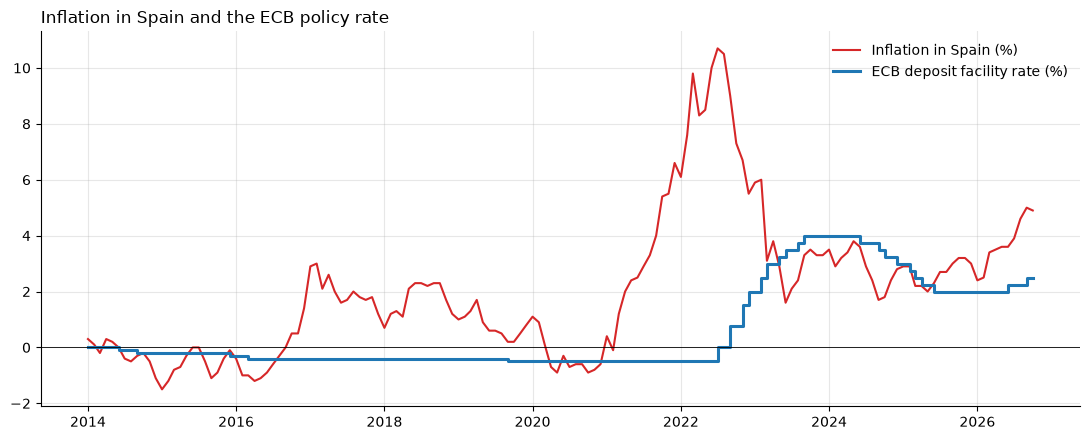

In [9]:
chart = df.copy()
chart.index = chart.index.to_timestamp()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(chart.index, chart["inflation_es"], color="tab:red", label="Inflation in Spain (%)")
ax.plot(chart.index, chart["ecb_rate"], color="tab:blue", lw=2.2, drawstyle="steps-post",
        label="ECB deposit facility rate (%)")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("Inflation in Spain and the ECB policy rate", loc="left")
ax.legend(frameon=False); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig("../images/01_inflation_vs_ecb_rate.png", dpi=150); plt.show()

When prices rose too fast (2022), the ECB raised its rate to cool the economy down. When inflation is low, it keeps the rate low.

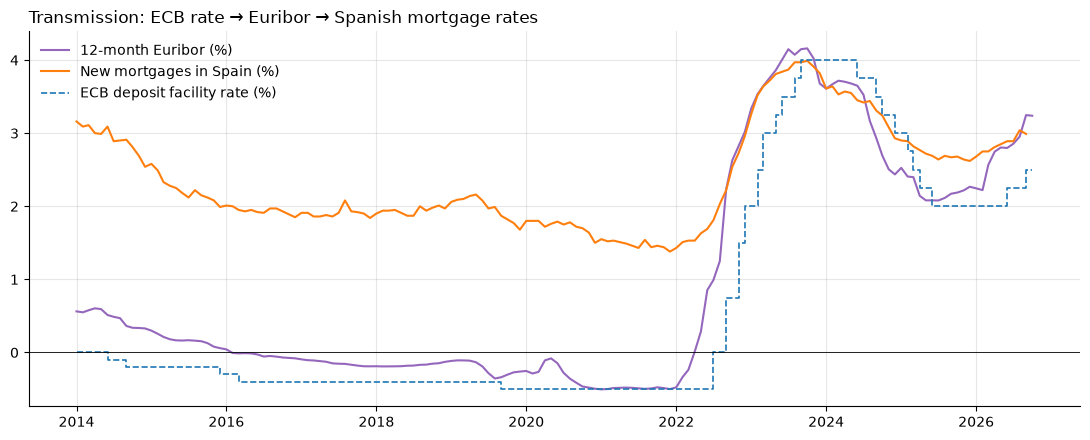

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(chart.index, chart["euribor_12m"], color="tab:purple", label="12-month Euribor (%)")
ax.plot(chart.index, chart["mortgage_rate_es"], color="tab:orange", label="New mortgages in Spain (%)")
ax.plot(chart.index, chart["ecb_rate"], color="tab:blue", lw=1.2, ls="--", drawstyle="steps-post",
        label="ECB deposit facility rate (%)")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("Transmission: ECB rate → Euribor → Spanish mortgage rates", loc="left")
ax.legend(frameon=False); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig("../images/02_euribor_vs_mortgage_rate.png", dpi=150); plt.show()

The Euribor anticipates ECB decisions (it started rising before the first hike in July 2022), and the rate on new Spanish mortgages follows it with a lag of a few months.

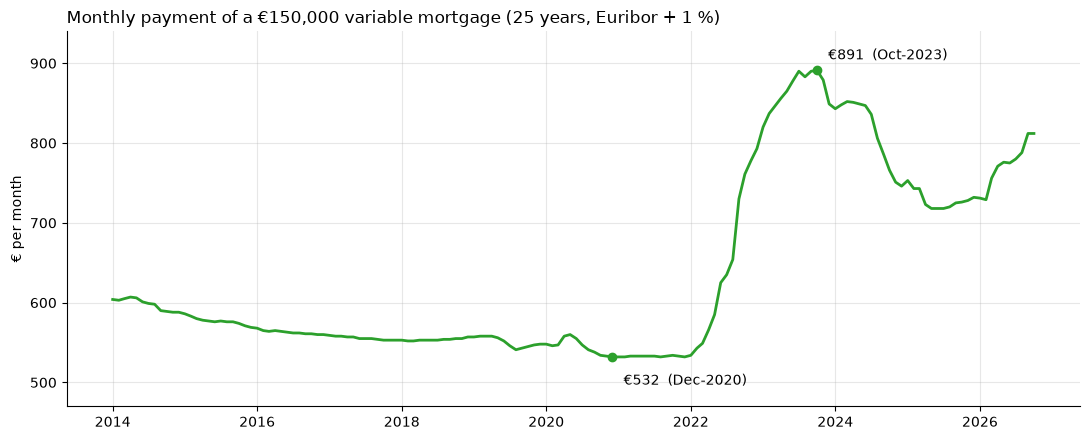

Lowest payment : 2020-12 -> 532 €
Highest payment: 2023-10 -> 891 €


In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(chart.index, chart["payment_150k"], color="tab:green", lw=2)
lo, hi = chart["payment_150k"].idxmin(), chart["payment_150k"].idxmax()
for d in (lo, hi):
    v = chart.loc[d, "payment_150k"]
    ax.annotate(f"€{v:.0f}  ({d:%b-%Y})", (d, v), xytext=(8, -20 if d == lo else 8),
                textcoords="offset points")
    ax.plot(d, v, "o", color="tab:green")
ax.set_title("Monthly payment of a €150,000 variable mortgage (25 years, Euribor + 1 %)", loc="left")
ax.set_ylim(470, 940); ax.set_ylabel("€ per month"); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig("../images/03_mortgage_payment_150k.png", dpi=150); plt.show()

print("Lowest payment :", df["payment_150k"].idxmin(), "->", int(df["payment_150k"].min()), "€")
print("Highest payment:", df["payment_150k"].idxmax(), "->", int(df["payment_150k"].max()), "€")

That monetary-policy decision reaches families directly: with the same loan, the monthly payment rose by about €360 (over €4,000 a year).

## 7. Problems found and how they were solved

| Problem | Solution |
|---|---|
| Reading the API directly with `pd.read_csv(url)` failed with an SSL certificate error on macOS | Use the `sdmx1` package, which handles the secure connection |
| Some requests failed (`400`, `404`) because the key was wrong or the series did not exist at monthly frequency | Read each dataflow's structure first (Section 2) and check which frequencies exist |
| The ECB rate is not monthly: it only changes on decision days | Carry each value forward until the next change and keep the month-end value (Section 4) |
| The inflation series stopped in December 2025 | The ECB moved it to a new dataflow (`HICP`); found it in the catalogue and checked both gave the same values |
| The ECB server sometimes answered `504 Gateway Time-out` | The client retries automatically with increasing waits |

## 8. Conclusion

- An official API plus an existing open-source package is a simple and reliable way to collect data, with no scraping and no code written from scratch for the protocol.
- Most of the work is finding the right series (catalogue → structure → key) and putting them on the same frequency.
- The result is a clean monthly dataset that updates itself: re-running the notebook downloads the latest data.